In [ ]:
!pip install tensorflow
!pip install importlib_resources

In [ ]:
import os
import tensorflow as tf
import tensorflow_datasets as tfds

data_dir = '/content/drive/MyDrive/tensorflow_datasets'

if not os.path.exists(data_dir):
  os.makedirs(data_dir, exist_ok=True)

# with_info=True дополнительно возвращает метаданные датасета (ds_info)
(train_ds, validation_ds, test_ds), ds_info = tfds.load(
  'tf_flowers',
  split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'],
  shuffle_files=True,
  as_supervised=True,
  with_info=True,
  data_dir=data_dir)

# Названия классов и их количество берём из метаданных
CLASS_NAMES = ds_info.features['label'].names
NUM_CLASSES = ds_info.features['label'].num_classes
print('Number of classes:', NUM_CLASSES)
print('Class names:', CLASS_NAMES)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /content/drive/MyDrive/tensorflow_datasets/tf_flowers/incomplete.4CEYUD_3.0.1/tf_flowers-train.tfrec…

Dataset tf_flowers downloaded and prepared to /content/drive/MyDrive/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Number of classes: 5
Class names: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


In [ ]:
names = ['training', 'validation', 'test']
for i, ds in enumerate((train_ds, validation_ds, test_ds)):
  count = 0
  for _ in ds:
    count += 1
  print('Number of', names[i], f'samples: {count}')


Number of training samples: 2936
Number of validation samples: 367
Number of test samples: 367


In [ ]:
import matplotlib.pyplot as plt

def visualize_samples(dataset, num_samples=10, buffer_sizesize=1000):
  num_rows = num_samples // 5 + (num_samples % 5 != 0)
  plt.figure(figsize=(15, 3 * num_rows))
  dataset = dataset.shuffle(buffer_size=buffer_sizesize).take(num_samples)
  for i, (image, label) in enumerate(dataset):
    plt.subplot(num_rows, 5, i + 1)
    plt.imshow(image)
    plt.title(f'label: {CLASS_NAMES[label.numpy()]}')
    plt.axis('off')
  plt.show()

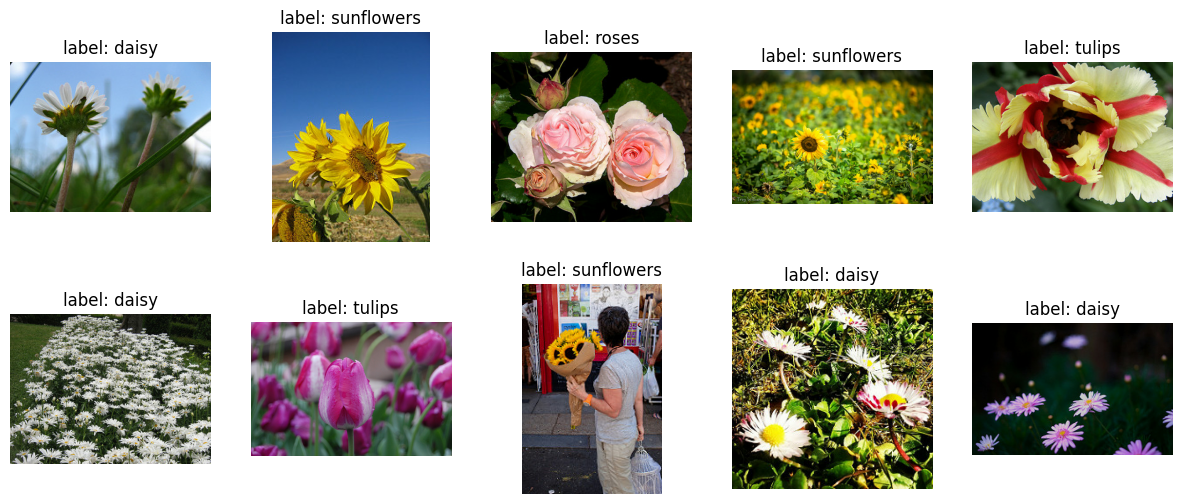

In [ ]:
visualize_samples(dataset=validation_ds, num_samples=10, buffer_sizesize=367)

In [ ]:
IMG_SIZE = 128

def preprocess(image, label):
  image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
  image = tf.cast(image, tf.float32) / 255.0
  return image, label


In [ ]:
BATCH_SIZE = 32

train_ds_processed = train_ds.map(preprocess,
                                  num_parallel_calls=tf.data.AUTOTUNE)
train_ds_processed = train_ds_processed.cache()
#train_ds_processed = train_ds_processed.shuffle(1000)
train_ds_processed = train_ds_processed.batch(BATCH_SIZE)
train_ds_processed = train_ds_processed.prefetch(tf.data.AUTOTUNE)

validation_ds_processed = validation_ds.map(preprocess,
                                            num_parallel_calls=tf.data.AUTOTUNE)
validation_ds_processed = validation_ds_processed.cache()
validation_ds_processed = validation_ds_processed.batch(BATCH_SIZE)
validation_ds_processed = validation_ds_processed.prefetch(tf.data.AUTOTUNE)

test_ds_processed = test_ds.map(preprocess,
                                num_parallel_calls=tf.data.AUTOTUNE)
test_ds_processed = test_ds_processed.cache()
test_ds_processed = test_ds_processed.batch(BATCH_SIZE)
test_ds_processed = test_ds_processed.prefetch(tf.data.AUTOTUNE)


In [ ]:
import keras
from keras.layers import Input, Conv2D, MaxPooling2D, Dense, Flatten, Dropout
from keras.models import Sequential

model = Sequential([
  Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
  Conv2D(32, (3, 3), activation='relu'),
  MaxPooling2D((2, 2)),
  Conv2D(64, (3, 3), activation='relu'),
  MaxPooling2D((2, 2)),
  Conv2D(128, (3, 3), activation='relu'),
  MaxPooling2D((2, 2)),
  Flatten(),
  Dense(128, activation='relu'),
  Dropout(0.5),
  Dense(NUM_CLASSES, activation='softmax')])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
  optimizer='adam',
  loss='sparse_categorical_crossentropy',
  metrics=['accuracy'])

In [ ]:
from keras.callbacks import EarlyStopping, ModelCheckpoint

EPOCHS = 10

os.makedirs('/content/drive/MyDrive/Models', exist_ok=True)

history = model.fit(
  train_ds_processed,
  epochs=EPOCHS,
  validation_data=validation_ds_processed,
  callbacks=[
      EarlyStopping(monitor='val_loss', patience=3),
      ModelCheckpoint('/content/drive/MyDrive/Models/best_model_flowers.keras',
                      save_best_only=True)])

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 29s 194ms/step - accuracy: 0.3937 - loss: 1.4138 - val_accuracy: 0.5395 - val_loss: 1.1514
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.5405 - loss: 1.1165 - val_accuracy: 0.6240 - val_loss: 0.9996
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6226 - loss: 0.9762 - val_accuracy: 0.6512 - val_loss: 0.9179
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6672 - loss: 0.8631 - val_accuracy: 0.6812 - val_loss: 0.8727
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.7142 - loss: 0.7643 - val_accuracy: 0.6730 - val_loss: 0.8269
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.7551 - loss: 0.6669 - val_accuracy: 0.6812 - val_loss: 0.8974
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7728 - loss: 0.5965 - val_accuracy: 0.6757 - val_loss: 0.8719
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8365 - loss: 0.4544 - val_accuracy: 0.6948 -

In [ ]:
from keras.models import load_model

loaded_model = load_model('/content/drive/MyDrive/Models/best_model_flowers.keras',
                          compile=False)

loaded_model.compile(
  optimizer='adam',
  loss='sparse_categorical_crossentropy',
  metrics=['accuracy'])

loaded_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
loss, accuracy = loaded_model.evaluate(test_ds_processed, verbose=False)
print(accuracy)


0.6512261629104614


In [ ]:
import numpy as np

def visualize_predictions(dataset_raw, num_samples=10, buffer_sizesize=1000):
  num_rows = num_samples // 5 + (num_samples % 5 != 0)
  plt.figure(figsize=(15, 3 * num_rows))

  visual_dataset = dataset_raw.shuffle(buffer_size=buffer_sizesize)
  visual_dataset = visual_dataset.take(num_samples).map(preprocess)

  images_to_predict = []
  labels_to_display = []

  for image, label in visual_dataset:
      images_to_predict.append(image)
      labels_to_display.append(label.numpy())

  batch_for_prediction = tf.stack(images_to_predict)

  # all_predictions имеет форму (num_samples, NUM_CLASSES)
  all_predictions = loaded_model.predict(batch_for_prediction, verbose=False)
  predicted_ids = np.argmax(all_predictions, axis=1)

  for i in range(num_samples):
    plt.subplot(num_rows, 5, i + 1)
    plt.imshow(images_to_predict[i].numpy())
    predicted_class = CLASS_NAMES[predicted_ids[i]]
    true_class = CLASS_NAMES[labels_to_display[i]]
    plt.title(f'tl: {true_class} pl: {predicted_class}')
    plt.axis('off')

  plt.show()

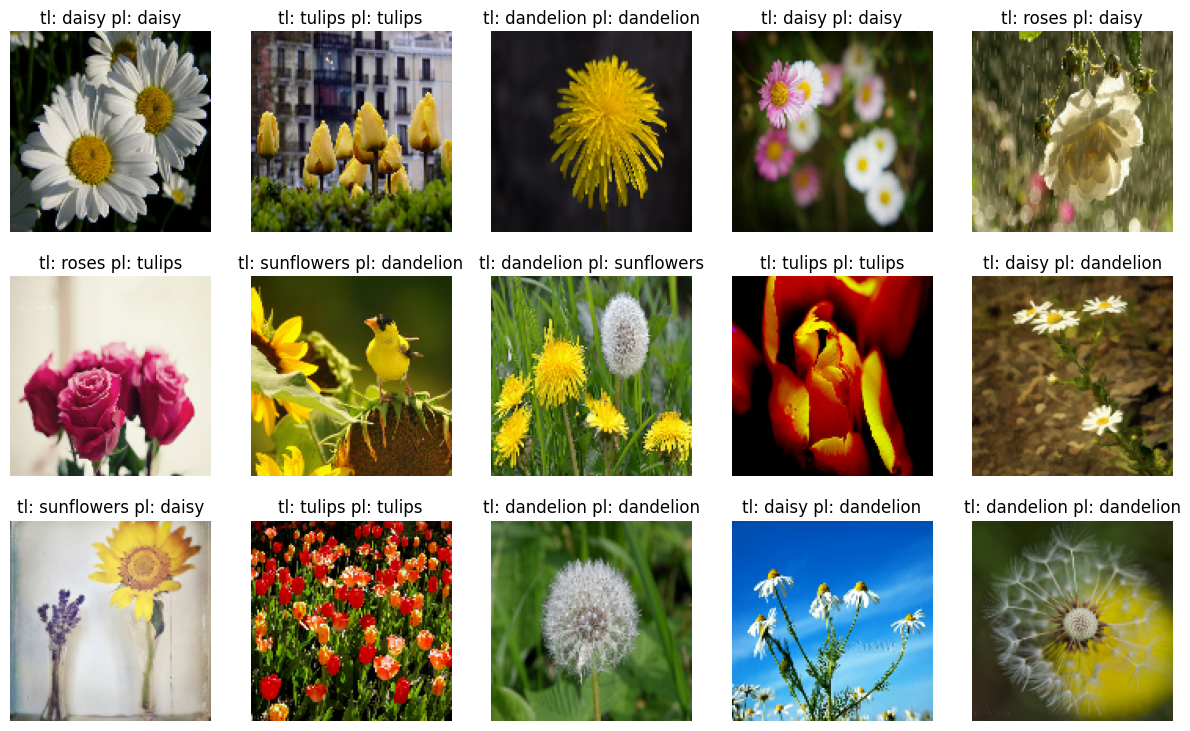

In [ ]:
visualize_predictions(dataset_raw=test_ds,
                      num_samples=15, buffer_sizesize=367)

In [ ]:
import io
from google.colab import files

def predict_uploaded_image(model, img_size=128):
  for filename, content in files.upload().items():
    image = tf.image.decode_image(content, channels=3)
    image = tf.image.resize(image, (img_size, img_size))
    image = tf.cast(image, tf.float32) / 255.0
    image_batch = tf.expand_dims(image, axis=0)

    prediction = model.predict(image_batch, verbose=False)
    probabilities = prediction[0]
    class_id = int(np.argmax(probabilities))
    predicted_class = CLASS_NAMES[class_id]
    probability = probabilities[class_id]

    plt.figure(figsize=(6, 6))
    plt.imshow(image.numpy())
    title = f'Predicted class: {predicted_class}\n'
    title += f'(Probability: {probability:.2f})'
    plt.title(title)
    plt.axis('off')
    plt.show()

In [ ]:
if 'loaded_model' in locals() or 'loaded_model' in globals():
  predict_uploaded_image(loaded_model, IMG_SIZE)
else:
  print('Model not found. Please ensure it is loaded.')
